# Divers

In [1502]:
# on fait une petite vérif...

from pathlib import Path        # pathlib est un module Python qui permet de manipuler les chemins de fichiers...

fichier = Path("/Users/sebastiensoncini/Documents/DataRockstars/Projet_Fil_Rouge_Foret/foret.csv")     # le world-data-2023.csv a été renommé en foret.csv

print(fichier.exists())         # on demande si le fichier existe

True


# Chargement, premières statistiques et nettoyage des données

### Observations

In [1503]:
# on regarde le nb de colonnes etc... sur le fichier csv d'origine

import pandas as pd

df = pd.read_csv("/Users/sebastiensoncini/Documents/DataRockstars/Projet_Fil_Rouge_Foret/foret.csv", sep=",")      # read_csv pour pour lire le fichier csv et le transformer en dataframe

pd.set_option('display.max_columns', None)
display(df.head())                                                                          # head() pour afficher les premières lignes
pd.reset_option('display.max_columns', None)

print(df.info())                                                                            # info() donne le nb de lignes, de colonnes, de valeurs non-null, le type de donnée...
print(df.columns)                                                                           # columns pour voir les noms des colonnes

display(df.describe())

,Country,Density\n(P/Km2),Abbreviation,Agricultural Land( %),Land Area(Km2),Armed Forces size,Birth Rate,Calling Code,Capital/Major City,Co2-Emissions,CPI,CPI Change (%),Currency-Code,Fertility Rate,Forested Area (%),Gasoline Price,GDP,Gross primary education enrollment (%),Gross tertiary education enrollment (%),Infant mortality,Largest city,Life expectancy,Maternal mortality ratio,Minimum wage,Official language,Out of pocket health expenditure,Physicians per thousand,Population,Population: Labor force participation (%),Tax revenue (%),Total tax rate,Unemployment rate,Urban_population,Latitude,Longitude
0,Afghanistan,60,AF,58.10%,"652,230","323,000",32.49,93.0,Kabul,"8,672",149.9,2.30%,AFN,4.47,2.10%,$0.70,"$19,101,353,833",104.00%,9.70%,47.9,Kabul,64.5,638.0,$0.43,Pashto,78.40%,0.28,"38,041,754",48.90%,9.30%,71.40%,11.12%,"9,797,273",33.939110,67.709953
1,Albania,105,AL,43.10%,"28,748","9,000",11.78,355.0,Tirana,"4,536",119.05,1.40%,ALL,1.62,28.10%,$1.36,"$15,278,077,447",107.00%,55.00%,7.8,Tirana,78.5,15.0,$1.12,Albanian,56.90%,1.20,"2,854,191",55.70%,18.60%,36.60%,12.33%,"1,747,593",41.153332,20.168331
2,Algeria,18,DZ,17.40%,"2,381,741","317,000",24.28,213.0,Algiers,"150,006",151.36,2.00%,DZD,3.02,0.80%,$0.28,"$169,988,236,398",109.90%,51.40%,20.1,Algiers,76.7,112.0,$0.95,Arabic,28.10%,1.72,"43,053,054",41.20%,37.20%,66.10%,11.70%,"31,510,100",28.033886,1.659626
3,Andorra,164,AD,40.00%,468,NaN,7.20,376.0,Andorra la Vella,469,NaN,NaN,EUR,1.27,34.00%,$1.51,"$3,154,057,987",106.40%,NaN,2.7,Andorra la Vella,NaN,NaN,$6.63,Catalan,36.40%,3.33,"77,142",NaN,NaN,NaN,NaN,"67,873",42.506285,1.521801
4,Angola,26,AO,47.50%,"1,246,700","117,000",40.73,244.0,Luanda,"34,693",261.73,17.10%,AOA,5.52,46.30%,$0.97,"$94,635,415,870",113.50%,9.30%,51.6,Luanda,60.8,241.0,$0.71,Portuguese,33.40%,0.21,"31,825,295",77.50%,9.20%,49.10%,6.89%,"21,061,025",-11.202692,17.873887


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 35 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Country                                    195 non-null    object 
 1   Density
(P/Km2)                            195 non-null    object 
 2   Abbreviation                               188 non-null    object 
 3   Agricultural Land( %)                      188 non-null    object 
 4   Land Area(Km2)                             194 non-null    object 
 5   Armed Forces size                          171 non-null    object 
 6   Birth Rate                                 189 non-null    float64
 7   Calling Code                               194 non-null    float64
 8   Capital/Major City                         192 non-null    object 
 9   Co2-Emissions                              188 non-null    object 
 10  CPI                       

,Birth Rate,Calling Code,Fertility Rate,Infant mortality,Life expectancy,Maternal mortality ratio,Physicians per thousand,Latitude,Longitude
count,189.000000,194.000000,188.000000,189.000000,187.000000,181.000000,188.000000,194.000000,194.000000
mean,20.214974,360.546392,2.698138,21.332804,72.279679,160.392265,1.839840,19.092351,20.232434
std,9.945774,323.236419,1.282267,19.548058,7.483661,233.502024,1.684261,23.961779,66.716110
min,5.900000,1.000000,0.980000,1.400000,52.800000,2.000000,0.010000,-40.900557,-175.198242
25%,11.300000,82.500000,1.705000,6.000000,67.000000,13.000000,0.332500,4.544175,-7.941496
50%,17.950000,255.500000,2.245000,14.000000,73.200000,53.000000,1.460000,17.273849,20.972652
75%,28.750000,506.750000,3.597500,32.700000,77.500000,186.000000,2.935000,40.124603,48.281523
max,46.080000,1876.000000,6.910000,84.500000,85.400000,1150.000000,8.420000,64.963051,178.065032


### Suppression des colonnes inutiles

In [1504]:
# liste des colonnes pas utile selon moi

colonnes_a_supprimer = [
    "Abbreviation",
    "Calling Code",
    "Capital/Major City",
    "Currency-Code",
    "Largest city",
    "Official language"
]

In [1505]:
df = df.drop(columns=colonnes_a_supprimer)                  # drop(columns) pour supprimer des colonnes, et il vaut mieux préciser quelles colonnes supprimer...

# on vérifie le résulat

print(df.columns.tolist())

# ainsi que le nb de colonnes

print("Nombre de colonnes :", len(df.columns))

['Country', 'Density\n(P/Km2)', 'Agricultural Land( %)', 'Land Area(Km2)', 'Armed Forces size', 'Birth Rate', 'Co2-Emissions', 'CPI', 'CPI Change (%)', 'Fertility Rate', 'Forested Area (%)', 'Gasoline Price', 'GDP', 'Gross primary education enrollment (%)', 'Gross tertiary education enrollment (%)', 'Infant mortality', 'Life expectancy', 'Maternal mortality ratio', 'Minimum wage', 'Out of pocket health expenditure', 'Physicians per thousand', 'Population', 'Population: Labor force participation (%)', 'Tax revenue (%)', 'Total tax rate', 'Unemployment rate', 'Urban_population', 'Latitude', 'Longitude']
Nombre de colonnes : 29


### Pays non identifié détecté - Recherche et correction

In [1506]:
# on constate dans le fichier excel et le csv d'origine... qu'il y a une ligne "S???" au lieu que ce soit un pays
# après recherche sur internet, le pays "S???" s'agit très probablement de Sao Tomé-et-Principe, une petite île près de l'Afrique centrale
# de plus la valeur dans "Land Area (km2) correspond bien"
# en Anglais, c'est São Tomé and Príncipe, nous allons le mettre dans le data, sans accent
# il s'agit de la ligne 152 dans le CSV d'origine
# mais dans pandas on commence à partir de la ligne zéro (au lieu de 1 dans csv ou excel...)
# et la ligne d'en-tête n'est pas une donnée pour pandas
# donc c'est la ligne numéro 150 dans pandas

df.iloc[150, df.columns.get_loc("Country")] = "Sao Tome and Principe"               # iloc[] pour sélectionner lignes ou colonnes en utilisant leur position numérique
                                                                                    # get_loc() pour trouver la position d'un élément dans un index
# on vérifie que la correction s'est bien faite

print(df.iloc[149:152][["Country", "Density\n(P/Km2)"]])

                   Country Density\n(P/Km2)
149             San Marino              566
150  Sao Tome and Principe              228
151           Saudi Arabia               16


In [1507]:
# on affiche toutes les valeurs de la ligne 150
print(df.iloc[150])

Country                                      Sao Tome and Principe
Density\n(P/Km2)                                               228
Agricultural Land( %)                                       50.70%
Land Area(Km2)                                                 964
Armed Forces size                                            1,000
Birth Rate                                                   31.54
Co2-Emissions                                                  121
CPI                                                         185.09
CPI Change (%)                                               7.90%
Fertility Rate                                                4.32
Forested Area (%)                                           55.80%
Gasoline Price                                                 NaN
GDP                                                  $429,016,605 
Gross primary education enrollment (%)                     106.80%
Gross tertiary education enrollment (%)                     13

In [1508]:
# on complète la latitude et la longitude de Sao Tome and Principe
df.loc[df["Country"] == "Sao Tome and Principe", "Latitude"] = 0.18636
df.loc[df["Country"] == "Sao Tome and Principe", "Longitude"] = 6.61308

# on vérifie la correction
print(df.loc[df["Country"] == "Sao Tome and Principe", ["Country", "Latitude", "Longitude"]])

                   Country  Latitude  Longitude
150  Sao Tome and Principe   0.18636    6.61308


### Colonne Forested Area

In [1509]:
# on regarde attentivement la colonne "Forested Area (%)"

# on regarde le nombre de valeurs manquantes

FM = df["Forested Area (%)"].isna().sum()
print(f"{FM} valeurs manquantes en tout")                       # isna() pour détecter les valeurs manquantes et sum() pour en faire le total ; isna() tout seul donnerait un True ou un False

# on regarde la proportion de valeurs manquantes

FP = df["Forested Area (%)"].isna().mean() * 100                # mean() pour calculer la moyenne et * 100 pour exprimer une valeur de pourcentage
print(f"{FP:.2f} % de valeurs manquantes sur toute la colonne")

7 valeurs manquantes en tout
3.59 % de valeurs manquantes sur toute la colonne


In [1510]:
# toujours la colonne des surfaces forestières

print(df["Forested Area (%)"].describe())                       # describe() fait un résumé statistique...

count        188
unique       161
top       43.10%
freq           3
Name: Forested Area (%), dtype: object


Résulats bizarres pour un describe() n'est-ce pas ? C'est parce que Pandas voit la colonne en catégorie objet.

In [1511]:
# les valeurs ne semblent pas être des nb pour vscode... regardons de plus près

print(df["Forested Area (%)"].head(20))                         # head(20) pour afficher les 20 premières lignes...

print(df["Forested Area (%)"].unique()[:20])                    # unique() pour donner les valeurs différentes de la colonne Forested Area... et [:20] pour donner les 20 premiers éléments du résultat

# remarquons que ici ça donne presque les mêmes résultats ; et on a des guillements donc du texte...

0      2.10%
1     28.10%
2      0.80%
3     34.00%
4     46.30%
5     22.30%
6      9.80%
7     11.70%
8     16.30%
9     46.90%
10    14.10%
11    51.40%
12     0.80%
13    11.00%
14    14.70%
15    42.60%
16    22.60%
17    59.70%
18    37.80%
19    72.50%
Name: Forested Area (%), dtype: object
['2.10%' '28.10%' '0.80%' '34.00%' '46.30%' '22.30%' '9.80%' '11.70%'
 '16.30%' '46.90%' '14.10%' '51.40%' '11.00%' '14.70%' '42.60%' '22.60%'
 '59.70%' '37.80%' '72.50%' '50.30%']


### Détection des valeurs manquantes (1)

In [1512]:
# on liste les colonnes qui ont des valauers manquantes, avec le nb de valeurs manquantes

import pandas as pd

valeurs_manquantes = df.isna().sum()

print(valeurs_manquantes[valeurs_manquantes > 0])       # si une colonne n'a pas de valeur manquante, on ne l'affiche pas
                                                        # remarque : ici on a une espèce de condition dans le [], on demande à Pandas de sélectionner certaines valeurs du dataframe
                                                        # la petite différence avec un vrai if, c'est que le if c'est pour tester une condition pour exécuter du code...

Agricultural Land( %)                         7
Land Area(Km2)                                1
Armed Forces size                            24
Birth Rate                                    6
Co2-Emissions                                 7
CPI                                          17
CPI Change (%)                               16
Fertility Rate                                7
Forested Area (%)                             7
Gasoline Price                               20
GDP                                           2
Gross primary education enrollment (%)        7
Gross tertiary education enrollment (%)      12
Infant mortality                              6
Life expectancy                               8
Maternal mortality ratio                     14
Minimum wage                                 45
Out of pocket health expenditure              7
Physicians per thousand                       7
Population                                    1
Population: Labor force participation (%

Remarque : quand on fait df.isna().sum(), Pandas renvoie une Series (une sorte de tableau à une dimension),

et cette Series conserve automatiquement les noms des colonnes du DataFrame d'origine comme index.

In [1513]:
# on vérifie qu'il n'y ait pas de pays en double

doublons = df.duplicated().sum()

print("Nombre de doublons :", doublons)

Nombre de doublons : 0


### Vérification des types de données

In [1514]:
# on vérifie les types de données de chaque colonne

print(df.dtypes)

Country                                       object
Density\n(P/Km2)                              object
Agricultural Land( %)                         object
Land Area(Km2)                                object
Armed Forces size                             object
Birth Rate                                   float64
Co2-Emissions                                 object
CPI                                           object
CPI Change (%)                                object
Fertility Rate                               float64
Forested Area (%)                             object
Gasoline Price                                object
GDP                                           object
Gross primary education enrollment (%)        object
Gross tertiary education enrollment (%)       object
Infant mortality                             float64
Life expectancy                              float64
Maternal mortality ratio                     float64
Minimum wage                                  

In [1515]:
# sauf que dans une colonne, il y a forcément toujours le même type ? Regardons plus précisément...

# regardons par exemple la colonne Land Area(Km2)

print(df["Land Area(Km2)"].apply(type).value_counts())              # apply(type) pour appliquer la fonction type() à caque valeur de la colonne Land Area ; fusionné avec un value_counts()

Land Area(Km2)
<class 'str'>      194
<class 'float'>      1
Name: count, dtype: int64


In [1516]:
# c'est déjà pas seulement de "type object"... affichons les 10 premières valeurs

print(df["Land Area(Km2)"].head(10).tolist())                       # tolist() pour transformer du Pandas en une liste classique

['652,230', '28,748', '2,381,741', '468', '1,246,700', '443', '2,780,400', '29,743', '7,741,220', '83,871']


### Conversion vers des valeurs numériques

In [1517]:
# toutes ces virgules, pandas ne voit pas cela comme des nombres...

# essayons de convertir une valeur au hasard...

valeur = "2,381,741"

valeur = valeur.replace(",", "")

print(valeur)

valeur = float(valeur)                  # si on écrit que float(valeur) le type de valeur ne changera pas au fond ; donc on écrit valeur = float(valeur)

print(valeur)

2381741
2381741.0


In [1518]:
# on convertit toutes les valeurs de land area en nombres entiers ; les virgules à supprimer viennent du format anglais...

df["Land Area(Km2)"] = (
    df["Land Area(Km2)"]
    .astype(str)                                                        # astype(str) pour convertir les valeurs en chaîne de caractères, donc en texte (par sécurité)
    .str.replace(",", "", regex=False)                                  # regex=False pour dire que je ne veux pas utiliser les expressions régulières, je veux simplement remplacer ce caractère exact
)

df["Land Area(Km2)"] = pd.to_numeric(
    df["Land Area(Km2)"],
    errors="coerce"                                                     # errors="coerce" ; si il n'y a pas de valeur alors on met NaN
).astype("Int64")                                                       # Int64 : nombres entiers et accepte les valeurs manquantes (<NA>)

# on vérifie que ça a fonctionné

print(df["Land Area(Km2)"].dtype)
print(df["Land Area(Km2)"].apply(type).value_counts())
print(df["Land Area(Km2)"].iloc[0])                                     # on vérifie un exemple pour être vraiment sûr
print(type(df["Land Area(Km2)"].iloc[0]))

Int64
Land Area(Km2)
<class 'float'>    195
Name: count, dtype: int64
652230
<class 'numpy.int64'>


### Détection de valeurs manquantes (2)

In [1519]:
# ça a l'air d'avoir fonctionné, on vérifie s'il y'a des valaurs manquantes

print(df["Land Area(Km2)"].isna().sum())

1


NaN signifie Not a Number (pas un nombre).

C'est une valeur spéciale utilisée en Python et notamment par NumPy et Pandas pour représenter une donnée manquante ou invalide.

Et surprenant : NaN est généralement représenté par un objet de type float ou int en Python.

In [1520]:
# il y a une valeur manquante, identifions la ligne concernée

print(df[df["Land Area(Km2)"].isna()])              # le df intérieur on sélectionne la colonne Land Area du df ; avec le isna() ça va donner une liste de True/False
                                                    # le df extérieur est une condition de filtrage ; on garde si isna() est vraie

                            Country Density\n(P/Km2) Agricultural Land( %)  \
133  Palestinian National Authority              847                   NaN   

     Land Area(Km2) Armed Forces size  Birth Rate Co2-Emissions  CPI  \
133            <NA>               NaN         NaN           NaN  NaN   

    CPI Change (%)  Fertility Rate  ... Out of pocket health expenditure  \
133            NaN             NaN  ...                              NaN   

    Physicians per thousand Population  \
133                     NaN        NaN   

    Population: Labor force participation (%) Tax revenue (%)  Total tax rate  \
133                                       NaN             NaN             NaN   

     Unemployment rate  Urban_population   Latitude  Longitude  
133                NaN               NaN  31.952162  35.233154  

[1 rows x 29 columns]


In [1521]:
# réaffichons les noms des colonnes

print(df.columns.tolist())                  # tolist() pour transformer un objet Pandas en liste classique...

['Country', 'Density\n(P/Km2)', 'Agricultural Land( %)', 'Land Area(Km2)', 'Armed Forces size', 'Birth Rate', 'Co2-Emissions', 'CPI', 'CPI Change (%)', 'Fertility Rate', 'Forested Area (%)', 'Gasoline Price', 'GDP', 'Gross primary education enrollment (%)', 'Gross tertiary education enrollment (%)', 'Infant mortality', 'Life expectancy', 'Maternal mortality ratio', 'Minimum wage', 'Out of pocket health expenditure', 'Physicians per thousand', 'Population', 'Population: Labor force participation (%)', 'Tax revenue (%)', 'Total tax rate', 'Unemployment rate', 'Urban_population', 'Latitude', 'Longitude']


### Détection de valeurs manquantes (3)

In [1522]:
# on regarde de nouveau les valeurs manquantes et on indique la proportion de valeurs manquantes pour chaque colonne

manquantes = df.isna().sum()

pourcentage = (manquantes / len(df)) * 100

print(pd.DataFrame({                                            # DataFrame() pour créer un DataFrame ; à partir de données qu'on donne à Pandas
    "Valeurs manquantes": manquantes,
    "Pourcentage": pourcentage
}))

                                           Valeurs manquantes  Pourcentage
Country                                                     0     0.000000
Density\n(P/Km2)                                            0     0.000000
Agricultural Land( %)                                       7     3.589744
Land Area(Km2)                                              1     0.512821
Armed Forces size                                          24    12.307692
Birth Rate                                                  6     3.076923
Co2-Emissions                                               7     3.589744
CPI                                                        17     8.717949
CPI Change (%)                                             16     8.205128
Fertility Rate                                              7     3.589744
Forested Area (%)                                           7     3.589744
Gasoline Price                                             20    10.256410
GDP                      

### Détection des colonnes avec du format texte

In [1523]:
# il y a encore beacoup de colonnes où pandas ne voit que du texte, vérifions de nouveau

colonnes_object = df.select_dtypes(include="object").columns                # select_dtypes() pour sélectionner selon le type de données

print(colonnes_object.tolist())

['Country', 'Density\n(P/Km2)', 'Agricultural Land( %)', 'Armed Forces size', 'Co2-Emissions', 'CPI', 'CPI Change (%)', 'Forested Area (%)', 'Gasoline Price', 'GDP', 'Gross primary education enrollment (%)', 'Gross tertiary education enrollment (%)', 'Minimum wage', 'Out of pocket health expenditure', 'Population', 'Population: Labor force participation (%)', 'Tax revenue (%)', 'Total tax rate', 'Unemployment rate', 'Urban_population']


### Définition des colonnes numériques

Définir juste 2 catégories, une catégorie de valeurs entières et une catégorie de valeurs décimales seraient imprudent.

En effet, certaines colonnes ont des valeurs contenants des symboles particuliers ($ ; % ou encore plusiers virgules).

De ce fait nous allons créer des catégories pour chaque cas particuliers.

### Définition des colonnes contenant des virgules - Suppression des virgules - Conversion vers des valeurs numériques

In [1524]:
# il y a des colonnes où les valeurs ont plein de virgules dus au format anglais mais ce sont des entiers... créons une catégorie pour ça

colonnes_virgules = [
    "Armed Forces size",
    "Co2-Emissions",
    "Population",
    "Urban_population"
]

# on applique alors le nettoyage, la conversion vers des nombres plus propre

for colonne in colonnes_virgules:
    df[colonne] = pd.to_numeric(
        df[colonne].astype("string").str.replace(",", "", regex=False),
        errors="coerce"
    ).astype("Int64")

# on vérifie que ça s'est bien passé

print(df[colonnes_virgules].dtypes)
print(df[colonnes_virgules].head())


Armed Forces size    Int64
Co2-Emissions        Int64
Population           Int64
Urban_population     Int64
dtype: object
   Armed Forces size  Co2-Emissions  Population  Urban_population
0             323000           8672    38041754           9797273
1               9000           4536     2854191           1747593
2             317000         150006    43053054          31510100
3               <NA>            469       77142             67873
4             117000          34693    31825295          21061025


### Définition des colonnes contenant des % - Suppression des % - Conversion vers des valeurs numériques

In [1525]:
# maintenant on fait pareil avec les colonnes qui contiennent des % ; qui contiennent des nombres décimaux

colonnes_pourcentage = [
    "Agricultural Land( %)",
    "CPI Change (%)",
    "Forested Area (%)",
    "Gross primary education enrollment (%)",
    "Gross tertiary education enrollment (%)",
    "Out of pocket health expenditure",
    "Population: Labor force participation (%)",
    "Tax revenue (%)",
    "Total tax rate",
    "Unemployment rate"
]

for colonne in colonnes_pourcentage:
    df[colonne] = (
        df[colonne].astype("string")
        .str.replace("%", "", regex=False)
        .astype(float)
    )

print(df[colonnes_pourcentage].dtypes)
print(df[colonnes_pourcentage].head())

Agricultural Land( %)                        float64
CPI Change (%)                               float64
Forested Area (%)                            float64
Gross primary education enrollment (%)       float64
Gross tertiary education enrollment (%)      float64
Out of pocket health expenditure             float64
Population: Labor force participation (%)    float64
Tax revenue (%)                              float64
Total tax rate                               float64
Unemployment rate                            float64
dtype: object
   Agricultural Land( %)  CPI Change (%)  Forested Area (%)  \
0                   58.1             2.3                2.1   
1                   43.1             1.4               28.1   
2                   17.4             2.0                0.8   
3                   40.0             NaN               34.0   
4                   47.5            17.1               46.3   

   Gross primary education enrollment (%)  \
0                               

### Définition des colonnes contenant des symboles dollard - Suppression des symboles - Conversion vers des valeurs numériques

In [1526]:
# pareil avec les colonnes avec $ ; qui contiennent des nombres décimaux

colonnes_dollars = [
    "Gasoline Price",
    "Minimum wage"
]

for colonne in colonnes_dollars:
    df[colonne] = (
        df[colonne].astype("string")
        .str.replace("$", "", regex=False)
        .str.strip()
        .astype(float)
    )

print(df[colonnes_dollars].dtypes)
print(df[colonnes_dollars].head())

Gasoline Price    float64
Minimum wage      float64
dtype: object
   Gasoline Price  Minimum wage
0            0.70          0.43
1            1.36          1.12
2            0.28          0.95
3            1.51          6.63
4            0.97          0.71


### Définition des colonnes contenant des caractères dollard et virgules - Suppresion de ces caractères - Conversion vers des valeurs numériques

In [1527]:
# maintenant la colonne GDP qui a des virgules et des $ ; les valeurs sont des entiers

df["GDP"] = (
    df["GDP"].astype("string")
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
    .astype("Int64")
)

print(df["GDP"].dtype)
print(df["GDP"].head())

Int64
0     19101353833
1     15278077447
2    169988236398
3      3154057987
4     94635415870
Name: GDP, dtype: Int64


### Vérification des types de valeurs pour chaque colonne

In [1528]:
# on refait un contrôle global

print(df.dtypes)

Country                                       object
Density\n(P/Km2)                              object
Agricultural Land( %)                        float64
Land Area(Km2)                                 Int64
Armed Forces size                              Int64
Birth Rate                                   float64
Co2-Emissions                                  Int64
CPI                                           object
CPI Change (%)                               float64
Fertility Rate                               float64
Forested Area (%)                            float64
Gasoline Price                               float64
GDP                                            Int64
Gross primary education enrollment (%)       float64
Gross tertiary education enrollment (%)      float64
Infant mortality                             float64
Life expectancy                              float64
Maternal mortality ratio                     float64
Minimum wage                                 f

### Conversion de la colonne Country en texte

In [1529]:
df["Country"] = df["Country"].astype("string")

In [1530]:
print(df["Country"].dtype)
print(df["Country"].head(10))

string
0            Afghanistan
1                Albania
2                Algeria
3                Andorra
4                 Angola
5    Antigua and Barbuda
6              Argentina
7                Armenia
8              Australia
9                Austria
Name: Country, dtype: string


Fichié nettoyé : il doit y avoir zéro valeurs manqunates :
- supprimer des colonnes
- supprimer des lignes
- ou mettre une valeur moyenne, médiane... et justifier

### Conversion de la colonne Density en valeurs numériques entières

In [1531]:
df["Density\n(P/Km2)"] = pd.to_numeric(
    df["Density\n(P/Km2)"]
    .astype("string")
    .str.replace(",", "", regex=False),
    errors="coerce"
).astype("Int64")

In [1532]:
print(df["Density\n(P/Km2)"].dtype)
print(df["Density\n(P/Km2)"].head(10))

Int64
0     60
1    105
2     18
3    164
4     26
5    223
6     17
7    104
8      3
9    109
Name: Density\n(P/Km2), dtype: Int64


### Conversion de la colonne CPI en nombres décimaux

In [1533]:
df["CPI"] = pd.to_numeric(
    df["CPI"],
    errors="coerce"
)

### Détection des valeurs manquantes (4)

In [1534]:
# maintenant on fait un diagnostique avec une belle mise en forme

manquantes = df.isna().sum()
pourcentage = (manquantes / len(df)) * 100

diagnostic = pd.DataFrame({
    "Valeurs manquantes": manquantes,
    "Pourcentage": pourcentage
})

print(
    diagnostic[diagnostic["Valeurs manquantes"] > 0]
    .sort_values("Pourcentage", ascending=False)
)

                                           Valeurs manquantes  Pourcentage
Minimum wage                                               45    23.076923
Tax revenue (%)                                            26    13.333333
Armed Forces size                                          24    12.307692
CPI                                                        20    10.256410
Gasoline Price                                             20    10.256410
Unemployment rate                                          19     9.743590
Population: Labor force participation (%)                  19     9.743590
CPI Change (%)                                             16     8.205128
Maternal mortality ratio                                   14     7.179487
Gross tertiary education enrollment (%)                    12     6.153846
Total tax rate                                             12     6.153846
Life expectancy                                             8     4.102564
Physicians per thousand  

### Traitement des valeurs manquantes

In [1535]:
# on supprime les colonnes inutiles pour l'analyse de la surface forestière

df = df.drop(columns=[
    "Minimum wage",
    "Tax revenue (%)",
    "Armed Forces size"
], errors="ignore")

In [1536]:
# le pays Palestine a très peu de valeurs

df[df["Country"] == "Palestinian National Authority"].T                     # .T pour transposer (transposition) dans Pandas
df[df["Country"] == "Palestinian National Authority"].isna().sum(axis=1)

133    22
dtype: int64

In [1537]:
# on supprime la ligne Palestine

df = df[df["Country"] != "Palestinian National Authority"]

In [1538]:
# on supprime les pays qui n'ont pas de données sur la surface forestière
df = df.dropna(subset=["Forested Area (%)"])

# Vérification
print("Nombre de lignes restantes :", len(df))
print("Valeurs manquantes :", df["Forested Area (%)"].isna().sum())

Nombre de lignes restantes : 188
Valeurs manquantes : 0


### Amélioration des titres des colonnes

In [1539]:
# on renomme les colonnes pour ajouter des unités de mesure

df = df.rename(columns={

    "Country": "Country",
    "Density\n(P/Km2)": "Density (people/km²)",
    "Agricultural Land( %)": "Agricultural Land (%)",
    "Land Area(Km2)": "Land Area (km²)",
    "Birth Rate": "Birth Rate (births/1,000 people/year)",
    "Co2-Emissions": "CO2 Emissions (kt/year)",
    "CPI": "CPI (index)",
    "CPI Change (%)": "CPI Change (%)",
    "Fertility Rate": "Fertility Rate (children/woman)",
    "Forested Area (%)": "Forested Area (%)",
    "Gasoline Price": "Gasoline Price (USD/litre)",
    "GDP": "GDP (USD)",
    "Gross primary education enrollment (%)": "Gross Primary Education Enrollment (%)",
    "Gross tertiary education enrollment (%)": "Gross Tertiary Education Enrollment (%)",
    "Infant mortality": "Infant Mortality (deaths/1,000 live births)",
    "Life expectancy": "Life Expectancy (years)",
    "Maternal mortality ratio": "Maternal Mortality (deaths/100,000 live births)",
    "Out of pocket health expenditure": "Out-of-Pocket Health Expenditure (%)",
    "Physicians per thousand": "Physicians (per 1,000 people)",
    "Population": "Population (people)",
    "Population: Labor force participation (%)": "Labor Force Participation (%)",
    "Total tax rate": "Total Tax Rate (%)",
    "Unemployment rate": "Unemployment Rate (%)",
    "Urban_population": "Urban Population (people)",
    "Latitude": "Latitude (degrees)",
    "Longitude": "Longitude (degrees)"
})

### Détection de valeurs manquantes (5)

In [1540]:
manquantes = df.isna().sum()
pourcentage = (manquantes / len(df)) * 100

diagnostic = pd.DataFrame({
    "Valeurs manquantes": manquantes,
    "Pourcentage": pourcentage
})

display(
    diagnostic[diagnostic["Valeurs manquantes"] > 0]
    .sort_values("Pourcentage", ascending=False)
)

,Valeurs manquantes,Pourcentage
Gasoline Price (USD/litre),15,7.978723
CPI (index),13,6.914894
Labor Force Participation (%),13,6.914894
Unemployment Rate (%),13,6.914894
CPI Change (%),10,5.319149
"Maternal Mortality (deaths/100,000 live births)",8,4.255319
Total Tax Rate (%),6,3.191489
Gross Tertiary Education Enrollment (%),5,2.659574
Out-of-Pocket Health Expenditure (%),4,2.127660
Life Expectancy (years),2,1.063830


In [1541]:
# on sélectionne uniquement les colonnes numériques contenant des valeurs manquantes
colonnes_manquantes = df.select_dtypes(include="number").columns[
    df.select_dtypes(include="number").isna().any()
]

# on affiche les statistiques descriptives de ces colonnes uniquement
display(df[colonnes_manquantes].describe().T)

,count,mean,std,min,25%,50%,75%,max
"Birth Rate (births/1,000 people/year)",187.0,20.212406,9.884508,6.4,11.35,17.95,28.695,46.08
CO2 Emissions (kt/year),187.0,178740.802139,840942.434597,11.0,2448.0,12633.0,64311.5,9893038.0
CPI (index),175.0,144.1936,54.783998,99.03,113.67,124.74,155.925,550.93
CPI Change (%),178.0,5.704494,20.364295,-4.3,1.0,2.3,4.1,254.9
Fertility Rate (children/woman),187.0,2.687433,1.277258,0.98,1.7,2.24,3.58,6.91
Gasoline Price (USD/litre),173.0,1.000867,0.35891,0.0,0.76,0.98,1.23,2.0
Gross Primary Education Enrollment (%),187.0,102.627807,13.007706,23.4,99.15,102.6,108.05,142.5
Gross Tertiary Education Enrollment (%),183.0,37.963388,29.261022,0.8,12.15,31.2,63.15,136.6
"Infant Mortality (deaths/1,000 live births)",187.0,21.206417,19.356713,1.4,6.05,14.0,32.25,84.5
Life Expectancy (years),186.0,72.358602,7.425417,52.8,67.15,73.3,77.55,85.4


On a maintenant une bonne vision des données, la plupart des variables ont une moyenne nettement supérieure à la médiane : c'est souvent le signe d'une distribution asymétrique avec quelques valeurs très élevées.

De ce fait nous allons remplacer les valeurs manquantes par la valeur médiane de la colonne.

In [1542]:
# on sélectionne les colonnes numériques contenant des valeurs manquantes
colonnes_manquantes = df.select_dtypes(include="number").columns[
    df.select_dtypes(include="number").isna().any()
]

# on remplace les valeurs manquantes par la médiane arrondie à 2 décimales
for colonne in colonnes_manquantes:
    mediane = round(df[colonne].median(), 2)
    df[colonne] = df[colonne].fillna(mediane)

# on vérifie
print("Valeurs manquantes restantes :", df.isna().sum().sum())

Valeurs manquantes restantes : 0


# Nettoyage effectué : génération du fichier nettoyé en csv

### Générer du csv

In [1543]:
# maintenant qu'on a tout bien nettoyé, on fait un fichier csv avec tout ça

df.to_csv("foret_clean.csv", index=False)
print("Fichiers csv généré")

Fichiers csv généré


### Vérification de la position dans l'ordinateur

In [1544]:
# rien à voir... mais si on veut vérifier dans quel dossier on est actuellement sur l'ordinateur

import os

print(os.getcwd())

/Users/sebastiensoncini/Documents/DataRockstars/Projet_Fil_Rouge_Foret


# Requête SQL

In [1545]:
# on importe SQLite et on crée une base SQL qui servira pour la forêt...

import sqlite3

connexion = sqlite3.connect("foret.db")                 # connect() pour établir une connexion avec une base de données
                                                        # remarque : on peut créer la base de donnée directement dans la focntion connect()

In [1546]:
# on envoie le DataFrame dans SQL

df.to_sql("forest", connexion, if_exists="replace", index=False)                # to_sql() pour envoyer un dataframe Pandas vers une table SQL

188

In [1547]:
# on fait une 1ère requete SQL, on demande les pays avec la plus grande surface forestière
# les """...""" permettent de faire du texte à la ligne

requete = """
SELECT Country, "Forested Area (%)"
FROM forest
ORDER BY "Forested Area (%)" DESC
LIMIT 10
"""

resultat = pd.read_sql_query(requete, connexion)                    # read_sql_query pour executer une requête SQL

print(resultat)

                          Country  Forested Area (%)
0                        Suriname               98.3
1  Federated States of Micronesia               91.9
2                           Gabon               90.0
3                      Seychelles               88.4
4                           Palau               87.6
5                          Guyana               83.9
6                            Laos               82.1
7                 Solomon Islands               77.9
8                Papua New Guinea               74.1
9                         Finland               73.1


# Analyse exploratoire

### Statistiques divers

In [1548]:
# on regarde divers statistiques pour chaque colonne ; count = nb de valeurs non-manquantes ; std = écart-type

df.describe()

,Density (people/km²),Agricultural Land (%),Land Area (km²),"Birth Rate (births/1,000 people/year)",CO2 Emissions (kt/year),CPI (index),CPI Change (%),Fertility Rate (children/woman),Forested Area (%),Gasoline Price (USD/litre),...,"Maternal Mortality (deaths/100,000 live births)",Out-of-Pocket Health Expenditure (%),"Physicians (per 1,000 people)",Population (people),Labor Force Participation (%),Total Tax Rate (%),Unemployment Rate (%),Urban Population (people),Latitude (degrees),Longitude (degrees)
count,188.0,188.000000,188.0,188.000000,188.0,188.000000,188.000000,188.000000,188.000000,188.000000,...,188.000000,188.000000,188.000000,188.0,188.000000,188.000000,188.000000,188.0,188.000000,188.000000
mean,211.026596,39.117553,707977.117021,20.200372,177857.25,142.848404,5.523404,2.685053,32.015426,0.999202,...,150.558511,32.682447,1.812447,40563318.457447,62.656383,40.756915,6.752340,22529909.558511,18.963131,19.282684
std,656.33455,21.783052,1948924.742819,9.859424,838778.403177,53.076647,19.827119,1.274257,23.791331,0.344261,...,218.269033,18.895229,1.648583,147245817.457878,10.136059,20.279533,4.912592,75800726.537533,23.893000,66.896248
min,2.0,0.600000,26.0,6.400000,11.0,99.030000,-4.300000,0.980000,0.000000,0.000000,...,2.000000,0.200000,0.010000,11646.0,38.000000,8.000000,0.090000,5464.0,-40.900557,-175.198242
25%,34.75,21.700000,27810.0,11.375000,2480.0,114.367500,1.000000,1.705000,11.000000,0.787500,...,14.750000,17.750000,0.332500,2302779.0,56.650000,30.675000,3.470000,1159543.0,4.454079,-8.540292
50%,88.0,39.600000,131163.5,17.950000,12633.0,124.740000,2.300000,2.240000,32.000000,0.980000,...,53.000000,30.700000,1.410000,9187159.0,62.300000,37.200000,5.360000,4705795.0,17.125346,19.933678
75%,208.0,55.375000,541067.75,28.667500,63884.25,155.380000,3.825000,3.575000,48.175000,1.192500,...,178.500000,43.825000,2.897500,29462950.5,68.425000,47.800000,8.915000,15199107.0,39.567179,49.026716
max,8358.0,82.600000,17098240.0,46.080000,9893038.0,550.930000,254.900000,6.910000,98.300000,2.000000,...,1140.000000,81.600000,8.420000,1397715000.0,86.800000,219.600000,28.180000,842933962.0,64.963051,178.065032


In [1549]:
# on se penche sur la colonne Forested Area (%)

df["Forested Area (%)"].describe()

count    188.000000
mean      32.015426
std       23.791331
min        0.000000
25%       11.000000
50%       32.000000
75%       48.175000
max       98.300000
Name: Forested Area (%), dtype: float64

In [1550]:
# on regarde les 10 valeurs les plus élevés de surface forestière (%) ; à supprimer ; redondant...

df["Forested Area (%)"].sort_values(ascending=False).head(10)

167    98.3
111    91.9
61     90.0
154    88.4
132    87.6
71     83.9
92     82.1
159    77.9
135    74.1
59     73.1
Name: Forested Area (%), dtype: float64

In [1551]:
# on a eu les index des valeurs mais pas les pays concernés
# cette fois on veut les pays correspondant

df.loc[df["Forested Area (%)"].nlargest(10).index, ["Country", "Forested Area (%)"]]

# nlargest() permet de récupérer les N plus grandes valeurs d'une colonne d'un DataFrame

,Country,Forested Area (%)
167,Suriname,98.3
111,Federated States of Micronesia,91.9
61,Gabon,90.0
154,Seychelles,88.4
132,Palau,87.6
71,Guyana,83.9
92,Laos,82.1
159,Solomon Islands,77.9
135,Papua New Guinea,74.1
59,Finland,73.1


On remarque que beaucoup de pays très forestiers sont des États tropicaux ou insulaires, avec quelques exceptions comme la Finlande.

In [1552]:
# maintenant on regarde les pays avec le moins de forêt

df.loc[df["Forested Area (%)"].nsmallest(10).index, ["Country", "Forested Area (%)"]]

,Country,Forested Area (%)
130,Oman,0.0
141,Qatar,0.0
149,San Marino,0.0
51,Egypt,0.1
97,Libya,0.1
47,Djibouti,0.2
108,Mauritania,0.2
90,Kuwait,0.4
76,Iceland,0.5
151,Saudi Arabia,0.5


On retrouve beaucoup de pays arides ou désertiques, ce qui est assez logique.

### Corrélations en Forested Area (%) et les autres variables numériques

In [1553]:
# on cherche les corrélations entre Forested Area (%) et les autres données

df.corr(numeric_only=True)["Forested Area (%)"].sort_values(ascending=False)

# df : ton DataFrame
# corr() : calcule les corrélations entre les variables numériques
# numeric_only=True : ignore les colonnes non numériques, comme les noms des pays

Forested Area (%)                                  1.000000
Gross Primary Education Enrollment (%)             0.144590
Labor Force Participation (%)                      0.141251
Gasoline Price (USD/litre)                         0.128132
Total Tax Rate (%)                                 0.034468
Longitude (degrees)                                0.032747
CPI Change (%)                                     0.016062
Life Expectancy (years)                            0.005993
GDP (USD)                                         -0.000565
Gross Tertiary Education Enrollment (%)           -0.012696
Land Area (km²)                                   -0.014278
CO2 Emissions (kt/year)                           -0.027234
Urban Population (people)                         -0.034797
Population (people)                               -0.055625
Infant Mortality (deaths/1,000 live births)       -0.056808
Fertility Rate (children/woman)                   -0.063509
Birth Rate (births/1,000 people/year)   

Forest Area (%) et Agricultural Land (%) ont une corrélation négative modérée. 

Autrement dit, dans ce jeu de données, les pays ayant une plus grande proportion de terres agricoles ont tendance à avoir une proportion de forêt plus faible.

C'est assez logique intuitivement : agriculture et forêt peuvent être en concurrence pour l'utilisation des terres.

### Corrélation entre Forested Area (%) et les terres agricoles (%)

<Axes: xlabel='Agricultural Land (%)', ylabel='Forested Area (%)'>

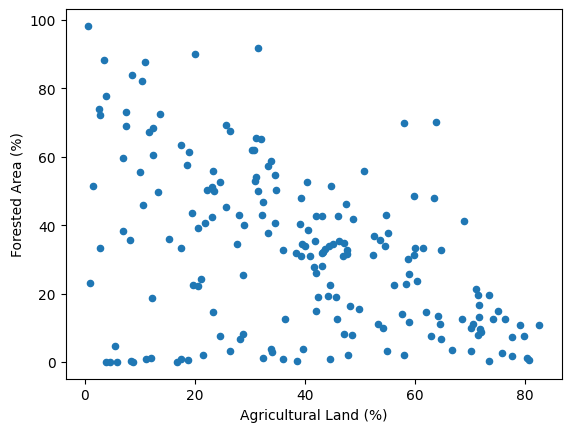

In [1554]:
# on fait un nuage de points entre la forêt et les terres agricoles

df.plot.scatter(x="Agricultural Land (%)", y="Forested Area (%)")

In [1555]:
# on crée une nouvelle colonne qui catégorise les terrains agricoles

df["Agriculture_categorie"] = pd.cut(                               # on crée une nouvelle colonne
    df["Agricultural Land (%)"],                                    # df["Agricultural Land( %)"] est la colonne qu'on veut catégoriser : le pourcentage de terres agricoles de chaque pays
    bins=[0, 20, 40, 60, 80, float("inf")],                         # partie qui définit les limites des catégories
    labels=["0-20", "20-40", "40-60", "60-80", ">80"]               # donne donc un nom lisible à chaque catégorie
)

# pd.cut() est une fonction de Pandas qui découpe des valeurs numériques en intervalles
# float("inf") : représente l'infini positif, donc permet de couvrir toutes les valeurs supérieures à 80

Par défaut, pd.cut() utilise des intervalles ouverts à gauche et fermés à droite. Ainsi, 20 appartient au premier intervalle, et 40 au deuxième.

In [1556]:
# on vérifie que ça a bien marché 

df[["Country", "Agricultural Land (%)", "Agriculture_categorie"]].head(10)

,Country,Agricultural Land (%),Agriculture_categorie
0,Afghanistan,58.1,40-60
1,Albania,43.1,40-60
2,Algeria,17.4,0-20
3,Andorra,40.0,20-40
4,Angola,47.5,40-60
5,Antigua and Barbuda,20.5,20-40
6,Argentina,54.3,40-60
7,Armenia,58.9,40-60
8,Australia,48.2,40-60
9,Austria,32.4,20-40


In [1557]:
# nb de pays dans chaque catégorie

df["Agriculture_categorie"].value_counts().sort_index()

Agriculture_categorie
0-20     43
20-40    53
40-60    56
60-80    33
>80       3
Name: count, dtype: int64

Remarque :
- sort_values() : trie des valeurs.
- value_counts() : compte combien de fois chaque valeur apparaît.

Le dernier groupe est donc beaucoup trop petit pour en tirer une conclusion solide. Il est analysable, mais avec prudence.

In [1558]:
# on calcule la médiane de Forested Area (%) pour chaque catégorie de terres agricoles

df.groupby("Agriculture_categorie", observed=True)["Forested Area (%)"].median()

Agriculture_categorie
0-20     49.80
20-40    40.60
40-60    31.25
60-80    12.60
>80       1.20
Name: Forested Area (%), dtype: float64

observed=True
- Il indique à Pandas de ne conserver que les catégories effectivement présentes dans les données, plutôt que d'inclure également les catégories définies mais absentes des observations.
- Par exemple, si aucun pays ne se trouve dans la catégorie >80, celle-ci ne sera pas affichée dans le résultat.

On observe une baisse très régulière :

49,8 → 40,6 → 31,25 → 12,6 → 1,2

Ici, le coefficient de corrélation de -0,435 prend sens : plus la proportion de terres agricoles est élevée, plus la médiane de couverture forestière tend à être faible.

Le groupe >80 % est à interpréter avec prudence puisqu'il ne contient que 3 pays, mais même sans lui, la tendance reste très nette.

### Corrélation entre Forested Area (%) et la densité de population (hab/km2)

In [1559]:
# on regarde la corrélation entre Forest Area (%) et la densité de population (P/km2)

df["Density (people/km²)"].corr(df["Forested Area (%)"])

np.float64(-0.10046637602399924)

Remarque : en Python, la première série appelle .corr() et la seconde est transmise à cette méthode.

La densité de population ne semble pas, à elle seule, expliquer beaucoup les différences de couverture forestière entre les pays.

Mais il y a une subtilité : la densité peut être très élevée dans de petits pays et très faible dans de grands pays, et notre graphique pourrait nous montrer une structure que le simple coefficient ne révèle pas très bien.

<Axes: xlabel='Density (people/km²)', ylabel='Forested Area (%)'>

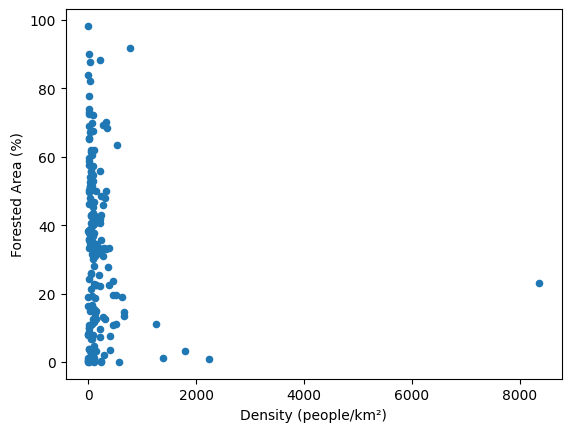

In [1560]:
# nuage de point

df.plot.scatter(
    x="Density (people/km²)",
    y="Forested Area (%)"
)

Le coefficient -0,069 nous dit seulement qu'il n'y a pratiquement pas de relation linéaire. Il ne dit pas qu'il n'y a aucune structure dans le nuage.

Or sur le graphique, il se dessine une sorte de triangle :
- énormément de pays sont concentrés dans les faibles densités ;
- quand la densité augmente, les valeurs de forêt semblent davantage se concentrer vers le bas ;
- mais il y a aussi quelques pays très denses qui étirent énormément l'axe horizontal.

Donc la densité ne présente pas une corrélation linéaire forte avec la forêt, pour autant le graphique mérite d'être étudié davantage.

Idée : zoomer sur les pays dont la densité est inférieure ou égale à 200 habitants/km².

<Axes: xlabel='Density (people/km²)', ylabel='Forested Area (%)'>

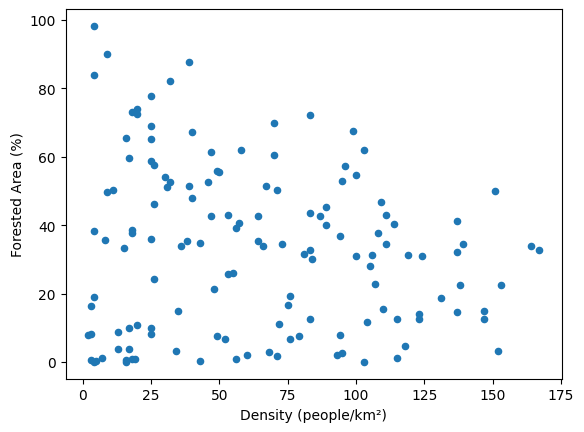

In [1561]:
# on enlève les pays extrêmement denses ; pays avec densité inférieur à 200 hab/km2

df[df["Density (people/km²)"] <= 200].plot.scatter(
    x="Density (people/km²)",
    y="Forested Area (%)"
)

En retirant les quelques pays avec une densité supérieure à 200, on remarque que :
- à faible densité, la forêt peut être presque n'importe où entre 0 et 100 % ;
- quand la densité augmente, on voit de moins en moins de pays avec une très forte couverture forestière ;
- mais la dispersion reste importante : une densité de 100–150 habitants/km² peut encore correspondre à 5 %, 30 % ou 60 % de forêt.

In [1562]:
# corrélation pour les pays avec densité inférieur à 200 hab/km2

df[df["Density (people/km²)"] <= 200]["Density (people/km²)"].corr(
    df[df["Density (people/km²)"] <= 200]["Forested Area (%)"]
)

np.float64(-0.1403051502776498)

La relation négative devient un peu plus visible pour les pays avec une densité inférieur à 200 hab/km2, mais elle reste faible.

Regardons la médiane de forêt selon les tranches de densité.

In [1563]:
# on crée les catégories

df["Densite_categorie"] = pd.cut(
    df["Density (people/km²)"],
    bins=[0, 20, 50, 100, 200, float("inf")],
    labels=["0-20", "20-50", "50-100", "100-200", ">200"]
)

In [1564]:
# on vérifie que la colonne Densité_Catégorie a bien été créee

df[["Country", "Density (people/km²)", "Densite_categorie"]].head(10)

,Country,Density (people/km²),Densite_categorie
0,Afghanistan,60,50-100
1,Albania,105,100-200
2,Algeria,18,0-20
3,Andorra,164,100-200
4,Angola,26,20-50
5,Antigua and Barbuda,223,>200
6,Argentina,17,0-20
7,Armenia,104,100-200
8,Australia,3,0-20
9,Austria,109,100-200


In [1565]:
# on calcule la médiane de Forested Area (%) pour chaque catégorie

df.groupby("Densite_categorie", observed=True)["Forested Area (%)"].median()

Densite_categorie
0-20       17.60
20-50      51.30
50-100     34.15
100-200    25.50
>200       25.40
Name: Forested Area (%), dtype: float64

Il y a bien une baisse globale de la médiane quand on passe des densités intermédiaires vers les densités élevées :

51,3 % → 34,15 % → 25,5 %

Mais il y a une grosse particularité : la catégorie 0–20 n'a qu'une médiane de 17,6 %, alors que la catégorie 20–50 monte à 51,3 %.

Donc ce n'est clairement pas une relation simplement "plus la densité augmente, moins il y a de forêt".

Il y a probablement plusieurs phénomènes mélangés : les pays très peu denses comprennent notamment des pays désertiques, tandis que certains pays peu ou moyennement denses sont extrêmement forestiers.

Regardons combien de pays se trouvent dans chaque catégorie, parce qu'une médiane de 20-50 n'a pas la même valeur analytique si elle repose sur 5 pays ou sur 50.

In [1566]:
df["Densite_categorie"].value_counts().sort_index()

Densite_categorie
0-20       32
20-50      31
50-100     42
100-200    32
>200       51
Name: count, dtype: int64

Les catégories sont assez bien représentées :
- 0–20 : 33 pays
- 20–50 : 31 pays
- 50–100 : 44 pays
- 100–200 : 32 pays
- plus de 200 : 48 pays

Donc aucune des médianes ne repose sur un tout petit échantillon. Elles sont donc toutes représentatives.

Remarque assez intéressante : la catégorie >200 contient même 48 pays, mais sa médiane de forêt remonte à 31,35 %. Ça confirme encore une fois que la relation avec la densité n'est pas monotone.

SSO : regarder le site d'origine de la foret.csv pour trouver des idées d'analyse...

# Visualisations

### Couverture forestière

In [1567]:
import pandas as pd
import matplotlib.pyplot as plt

In [1568]:
top_10_foret = df.nlargest(10, "Forested Area (%)")

In [1569]:
print(top_10_foret[["Country", "Forested Area (%)"]])

                            Country  Forested Area (%)
167                        Suriname               98.3
111  Federated States of Micronesia               91.9
61                            Gabon               90.0
154                      Seychelles               88.4
132                           Palau               87.6
71                           Guyana               83.9
92                             Laos               82.1
159                 Solomon Islands               77.9
135                Papua New Guinea               74.1
59                          Finland               73.1


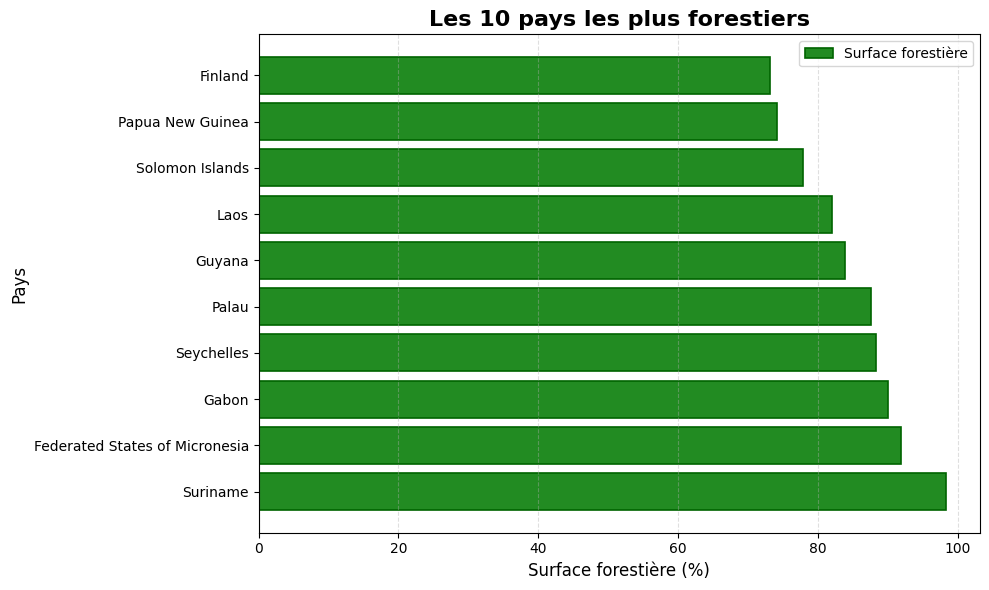

In [1570]:
plt.figure(figsize=(10, 6))                                                             # on crée une nouvelle figure

plt.barh(                                                                               # on dit que la figure sera des barres horizontales
    top_10_foret["Country"],
    top_10_foret["Forested Area (%)"],
    color="forestgreen",
    edgecolor="darkgreen",
    linewidth=1.2,
    label="Surface forestière"
)

plt.title("Les 10 pays les plus forestiers", fontsize=16, fontweight="bold")            # fontsize=16 : définit la taille du texte à 16 points ; fontweight="bold" : met le texte en gras
plt.xlabel("Surface forestière (%)", fontsize=12)
plt.ylabel("Pays", fontsize=12)

plt.grid(axis="x", linestyle="--", alpha=0.4)                                           # alpha=0.4 : pour une grille assez transparente
plt.legend()

plt.tight_layout()
plt.show()

Remarque avec plt.barh(), l'ordre des arguments est défini par Matplotlib :
- Premier argument : les catégories sur l'axe vertical (ordonnée, Y).
- Deuxième argument : les valeurs numériques sur l'axe horizontal (abscisse, X).

Analyse des 10 pays ayant la plus forte couverture forestière :

Ce graphique présente les dix pays dont la proportion de surface forestière est la plus élevée dans notre jeu de données.

Le Suriname arrive en première position, avec **98,3 % de sa superficie couverte par des forêts**, suivi des États fédérés de Micronésie (91,9 %) et du Gabon (90 %). La plupart des pays représentés sont des États tropicaux ou insulaires, tandis que la Finlande constitue un exemple de pays nordique fortement boisé.

Ces résultats mettent en évidence de fortes différences géographiques dans la couverture forestière. Ils montrent également que certains pays possèdent une proportion de forêts très proche de la totalité de leur territoire.

**Limite de l'analyse :** ce graphique présente uniquement les proportions de surface forestière. Il ne renseigne pas sur la superficie forestière totale en kilomètres carrés, ni sur l'évolution de la forêt dans le temps. Un petit pays peut avoir une couverture forestière très élevée sans posséder une grande superficie forestière totale.

Cette première visualisation permet donc d'identifier les pays les plus forestiers en proportion, mais des analyses complémentaires seront nécessaires pour comprendre les facteurs associés à ces différences.

### Terres agricoles et surface forestière

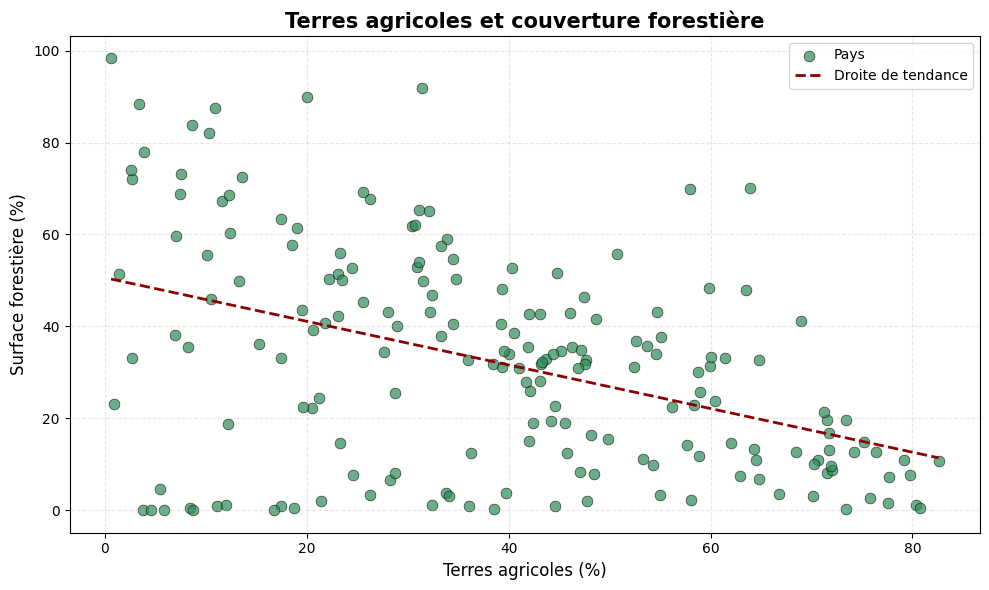

In [1571]:
# Sélection des deux variables
donnees = df[["Agricultural Land (%)", "Forested Area (%)"]].dropna()

# Définition de x et y
x = donnees["Agricultural Land (%)"]
y = donnees["Forested Area (%)"]

import numpy as np

plt.figure(figsize=(10, 6))

pente, ordonnee_origine = np.polyfit(x, y, 1)

# on fait la droite de tendance
x_droite = np.linspace(x.min(), x.max(), 100)                           # cette ligne utilise NumPy pour créer 100 valeurs régulièrement espacées entre la plus petite et la plus grande valeur de x
y_droite = pente * x_droite + ordonnee_origine                          # linspace() signifie linear space, cette fonction crée 100 valeurs régulièrement espacées entre les deux bornes, en incluant les bornes par défaut
                                                                        # y_droite sert à calculer les valeurs correspondant aux valeurs de x_droite pour tracer la droite de régression sur le graphique
# on fait un nuage de points                                            # ordonnee_origine : la valeur de y_droite lorsque x_droite = 0, c'est-à-dire l'endroit où la droite coupe l'axe vertical
plt.scatter(
    x, y,
    color="seagreen",
    marker="o",
    s=60,                                                               # taille des points, exprimée en points carrés
    alpha=0.7,                                                          # transparence : 0 = invisible, 1 = opaque
    edgecolors="black",
    linewidths=0.5,
    label="Pays"
)

plt.plot(
    x_droite,
    y_droite,
    color="darkred",
    linestyle="--",
    linewidth=2,
    label="Droite de tendance"
)

plt.title(
    "Terres agricoles et couverture forestière",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Terres agricoles (%)", fontsize=12)
plt.ylabel("Surface forestière (%)", fontsize=12)

plt.grid(linestyle="--", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Analyse de la relation entre les terres agricoles et la couverture forestière :

Ce nuage de points représente la proportion de terres agricoles en abscisse et la proportion de surface forestière en ordonnée, pour les pays présents dans notre jeu de données. Chaque point correspond à un pays. La droite rouge en pointillés représente la tendance linéaire générale.

On observe une **tendance négative** : les pays ayant une proportion importante de terres agricoles ont généralement une couverture forestière plus faible. Cette observation est cohérente avec le coefficient de corrélation de Pearson calculé précédemment, égal à environ **−0,435**, qui indique une corrélation négative modérée.

Toutefois, les points restent dispersés autour de la droite. Certains pays possèdent une couverture forestière élevée malgré une proportion non négligeable de terres agricoles. La relation n'est donc pas systématique et d'autres facteurs, comme le climat, la géographie ou les politiques d'aménagement du territoire, peuvent également intervenir.

**Limite de l'analyse :** cette corrélation ne permet pas d'établir un lien de causalité. Elle ne démontre pas que l'augmentation des terres agricoles entraîne directement une diminution de la couverture forestière. De plus, les deux variables sont exprimées en pourcentage du territoire : leur relation peut en partie refléter la répartition des terres entre différents usages.

En conclusion, la proportion de terres agricoles apparaît comme une variable intéressante à étudier pour comprendre les différences de couverture forestière entre les pays, mais cette relation doit être interprétée avec prudence.

### Diagramme en moustache

In [1572]:
categories = ["0-20", "20-40", "40-60", "60-80", ">80"]

donnees_boxplot = [
    df.loc[
        df["Agriculture_categorie"] == categorie,
        "Forested Area (%)"
    ].dropna()
    for categorie in categories
]

In [1573]:
for categorie, donnees in zip(categories, donnees_boxplot):
    print(categorie, ":", len(donnees), "pays")

0-20 : 43 pays
20-40 : 53 pays
40-60 : 56 pays
60-80 : 33 pays
>80 : 3 pays


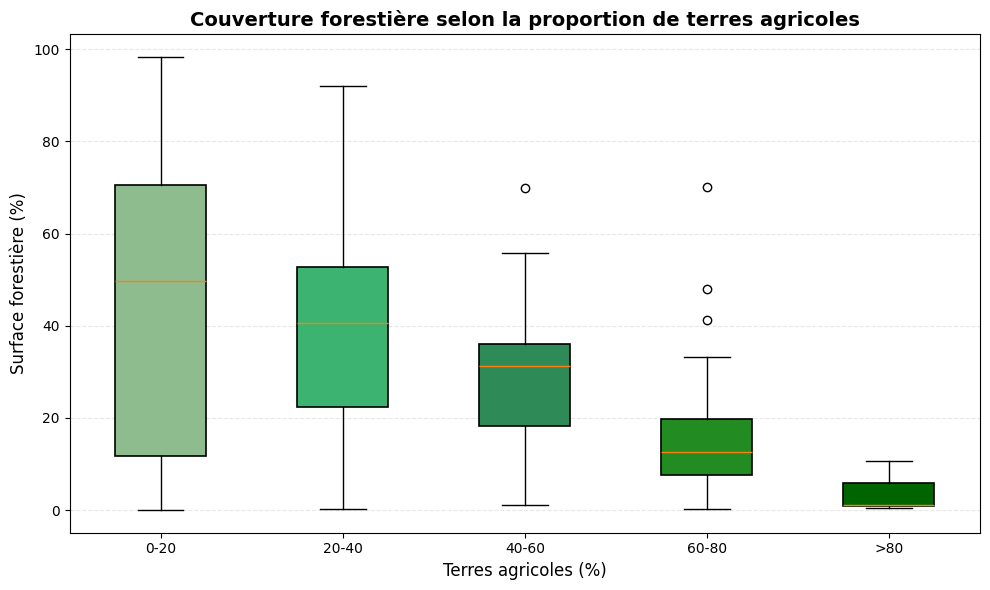

In [1574]:
plt.figure(figsize=(10, 6))

boites = plt.boxplot(
    donnees_boxplot,
    tick_labels=categories,
    patch_artist=True
)

couleurs = [
    "darkseagreen",
    "mediumseagreen",
    "seagreen",
    "forestgreen",
    "darkgreen"
]

for boite, couleur in zip(boites["boxes"], couleurs):
    boite.set_facecolor(couleur)
    boite.set_edgecolor("black")
    boite.set_linewidth(1.2)

plt.title(
    "Couverture forestière selon la proportion de terres agricoles",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Terres agricoles (%)", fontsize=12)
plt.ylabel("Surface forestière (%)", fontsize=12)

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

Analyse de la couverture forestière selon la proportion de terres agricoles

Ce diagramme en boîtes (*boxplot*) compare la distribution de la couverture forestière entre cinq groupes de pays, définis selon la proportion de terres agricoles dans leur territoire.

On observe une **diminution progressive de la médiane de couverture forestière** lorsque la proportion de terres agricoles augmente. Elle passe d'environ 49,8 % pour les pays dont les terres agricoles représentent entre 0 et 20 % du territoire, à 40,6 %, puis 31,25 % et 12,6 % dans les catégories suivantes. Pour les pays dépassant 80 % de terres agricoles, elle atteint seulement 1,2 %.

La dispersion des valeurs est également importante dans les premières catégories : certains pays ont une couverture forestière très élevée, tandis que d'autres en ont très peu. À l'inverse, les pays ayant une forte proportion de terres agricoles présentent généralement une couverture forestière plus faible.

Les points isolés visibles sur le graphique correspondent à des valeurs considérées comme atypiques par la règle utilisée pour construire le boxplot. Ils ne sont pas nécessairement erronés et peuvent représenter des situations géographiques particulières.

**Limite de l'analyse :** la dernière catégorie ne contient que trois pays. Sa médiane et sa distribution doivent donc être interprétées avec prudence. Par ailleurs, cette comparaison met en évidence une association statistique, mais ne permet pas d'établir une causalité entre agriculture et déforestation.

En conclusion, cette visualisation renforce le constat précédent : dans notre jeu de données, une proportion élevée de terres agricoles est associée à une couverture forestière généralement plus faible.

### Carte de chaleur des corrélations

In [1575]:
variables = [
    "Forested Area (%)",
    "Agricultural Land (%)",
    "Density (people/km²)",
    "Land Area (km²)",
    "Population (people)",
    "GDP (USD)"
]

correlations = df[variables].corr()

Le script limite volontairement l'analyse aux colonnes mises dans la liste variables, et c'est la sélection effectuée avant ou après .corr() qui détermine les colonnes prises en compte dans le résultat.

In [1576]:
print(correlations.round(2))

                       Forested Area (%)  Agricultural Land (%)  \
Forested Area (%)                   1.00                  -0.43   
Agricultural Land (%)              -0.43                   1.00   
Density (people/km²)               -0.10                  -0.11   
Land Area (km²)                    -0.01                  -0.03   
Population (people)                -0.06                   0.12   
GDP (USD)                          -0.00                   0.05   

                       Density (people/km²)  Land Area (km²)  \
Forested Area (%)                     -0.10            -0.01   
Agricultural Land (%)                 -0.11            -0.03   
Density (people/km²)                   1.00            -0.08   
Land Area (km²)                       -0.08             1.00   
Population (people)                    0.01             0.45   
GDP (USD)                             -0.01             0.55   

                       Population (people)  GDP (USD)  
Forested Area (%)        

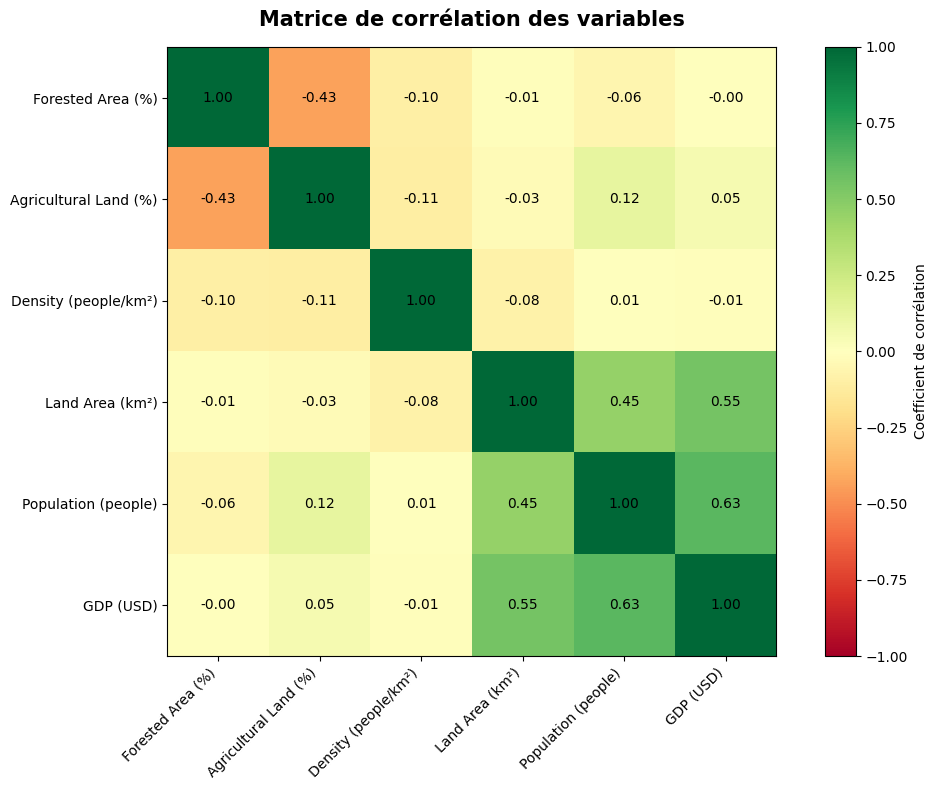

In [1577]:
plt.figure(figsize=(11, 8))

image = plt.imshow(
    correlations,
    cmap="RdYlGn",
    vmin=-1,
    vmax=1
)

# Noms des variables sur les axes
plt.xticks(
    range(len(variables)),
    variables,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(variables)),
    variables
)

# Valeurs des corrélations dans chaque case
for i in range(len(variables)):
    for j in range(len(variables)):
        valeur = correlations.iloc[i, j]

        plt.text(
            j, i,
            f"{valeur:.2f}",
            ha="center",
            va="center",
            color="black",
            fontsize=10
        )

# Barre de couleurs
plt.colorbar(image, label="Coefficient de corrélation")

plt.title(
    "Matrice de corrélation des variables",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.tight_layout()
plt.show()

Analyse de la matrice de corrélation

Cette matrice permet d'étudier les relations linéaires entre six variables du jeu de données. Les couleurs représentent le sens et l'intensité des corrélations : les teintes orangées indiquent des relations négatives, tandis que les teintes vertes indiquent des relations positives.

**1. Relation entre agriculture et forêt**

La corrélation entre les terres agricoles et la couverture forestière est de **−0,43**. Il s'agit d'une corrélation négative modérée : les pays présentant une proportion élevée de terres agricoles ont généralement une proportion de forêt plus faible. Cette observation est cohérente avec les graphiques précédents.

**2. Relations entre population, superficie et PIB**

La population et le PIB présentent une corrélation positive de **0,63**. La superficie du pays est également corrélée positivement au PIB (**0,55**) et à la population (**0,45**). Ces résultats indiquent que les pays les plus vastes ont tendance, dans cet échantillon, à avoir une population et un PIB plus importants, sans que cela soit systématique.

**3. Faibles corrélations avec la densité de population**

La densité de population présente une corrélation de seulement **−0,07** avec la couverture forestière. Sa relation linéaire avec cette variable est donc très faible. La superficie totale du pays présente également une corrélation presque nulle avec la couverture forestière (**−0,01**).

**Limites de l'analyse**

Les coefficients mesurent des associations linéaires et ne permettent pas de démontrer une causalité. Une corrélation proche de zéro n'exclut pas non plus l'existence d'une relation non linéaire. Enfin, les résultats dépendent des pays présents dans le jeu de données et des valeurs manquantes.

**Conclusion :** parmi les variables représentées, la proportion de terres agricoles est celle qui présente la corrélation la plus marquée avec la couverture forestière. Les relations entre population, superficie et PIB sont également intéressantes, tandis que la densité de population et la superficie totale semblent peu liées à la proportion forestière.

# Suite de l'analyse

### Couverture forestière et richesse des pays

In [1578]:
print(df[["Country", "GDP (USD)", "Population (people)"]].head(10))

               Country      GDP (USD)  Population (people)
0          Afghanistan    19101353833             38041754
1              Albania    15278077447              2854191
2              Algeria   169988236398             43053054
3              Andorra     3154057987                77142
4               Angola    94635415870             31825295
5  Antigua and Barbuda     1727759259                97118
6            Argentina   449663446954             44938712
7              Armenia    13672802158              2957731
8            Australia  1392680589329             25766605
9              Austria   446314739528              8877067


In [1579]:
df["GDP_per_capita (USD)"] = df["GDP (USD)"] / df["Population (people)"]

In [1580]:
print(df[["Country", "GDP (USD)", "Population (people)", "GDP_per_capita (USD)"]].head(10))

               Country      GDP (USD)  Population (people)  \
0          Afghanistan    19101353833             38041754   
1              Albania    15278077447              2854191   
2              Algeria   169988236398             43053054   
3              Andorra     3154057987                77142   
4               Angola    94635415870             31825295   
5  Antigua and Barbuda     1727759259                97118   
6            Argentina   449663446954             44938712   
7              Armenia    13672802158              2957731   
8            Australia  1392680589329             25766605   
9              Austria   446314739528              8877067   

   GDP_per_capita (USD)  
0            502.115487  
1           5352.857411  
2           3948.343279  
3          40886.391162  
4            2973.59116  
5          17790.309304  
6          10006.148974  
7           4622.733493  
8          54049.828812  
9          50277.275087  


In [1581]:
print(df[["GDP_per_capita (USD)", "Forested Area (%)"]].isna().sum())

GDP_per_capita (USD)    0
Forested Area (%)       0
dtype: int64


In [1582]:
donnees_pib_foret = df[
    ["Country", "GDP_per_capita (USD)", "Forested Area (%)"]
].dropna()

print("Nombre de pays retenus :", len(donnees_pib_foret))

Nombre de pays retenus : 188


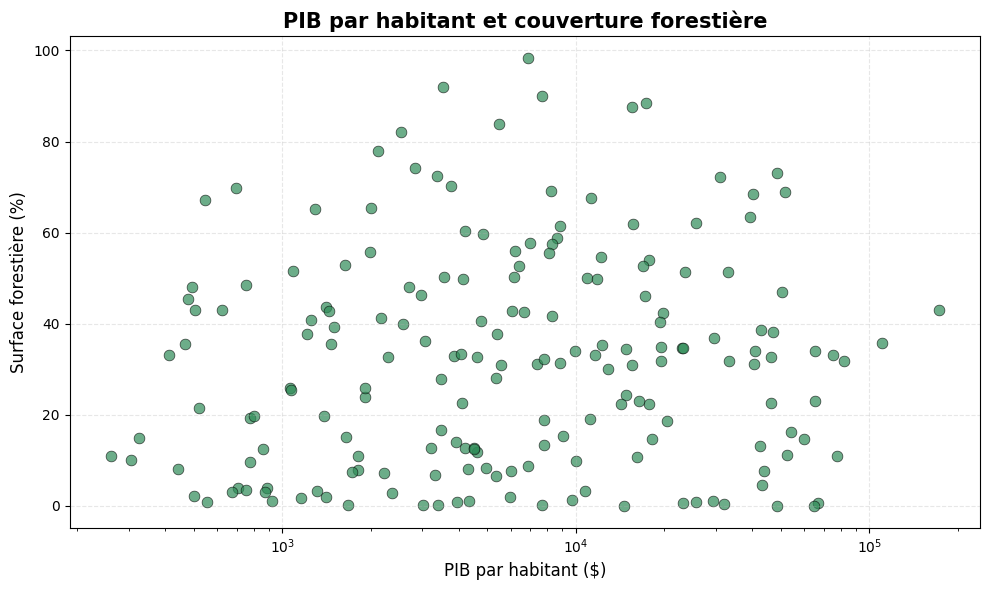

In [1583]:
plt.figure(figsize=(10, 6))

plt.scatter(
    donnees_pib_foret["GDP_per_capita (USD)"],
    donnees_pib_foret["Forested Area (%)"],
    color="seagreen",
    s=60,
    alpha=0.7,
    edgecolors="black",
    linewidths=0.5
)

plt.title(
    "PIB par habitant et couverture forestière",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("PIB par habitant ($)", fontsize=12)
plt.ylabel("Surface forestière (%)", fontsize=12)

plt.xscale("log")

plt.grid(linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [1584]:
donnees_pib_foret["GDP_per_capita (USD)"].corr(
    donnees_pib_foret["Forested Area (%)"]
)

np.float64(-0.004934551862409298)

Analyse de la relation entre le PIB par habitant et la couverture forestière

Ce nuage de points compare le PIB par habitant à la proportion de surface forestière de 188 pays. Une échelle logarithmique a été utilisée sur l'axe horizontal afin de mieux répartir les pays dont les niveaux de PIB par habitant sont très différents.

Le graphique ne fait apparaître aucune tendance linéaire évidente. Les pays ayant un PIB par habitant élevé présentent des proportions de couverture forestière très variables, tout comme les pays moins riches.

Cette observation est confirmée par le coefficient de corrélation de Pearson, d'environ **−0,005**, qui est extrêmement proche de zéro. Dans cet échantillon, il n'existe donc pratiquement aucune association linéaire entre le PIB par habitant et la couverture forestière.

**Limites de l'analyse :** une corrélation proche de zéro ne permet pas d'exclure une éventuelle relation non linéaire. De plus, le PIB par habitant ne mesure pas à lui seul les politiques environnementales, l'utilisation des sols ou les conditions géographiques d'un pays.

En conclusion, le PIB par habitant ne semble pas constituer, à lui seul, un indicateur pertinent pour expliquer les différences de couverture forestière entre les pays étudiés.

### Pays s'écartant de la tendance agriculture-forêt

L'idée est de comparer, pour chaque pays, sa couverture forestière réelle à celle que notre droite de tendance prédit à partir de sa proportion de terres agricoles.

On appelle cette différence le résidu : Résidu = Valeur observée - Valeur prédite

- Résidu positif : le pays possède davantage de forêt que ce que prédit la droite.
- Résidu négatif : il possède moins de forêt que ce que prédit la droite.
- Résidu proche de zéro : il est proche de la tendance générale.

In [1585]:
donnees_residus = df[
    ["Country", "Agricultural Land (%)", "Forested Area (%)"]
].dropna().copy()

print("Nombre de pays retenus :", len(donnees_residus))

Nombre de pays retenus : 188


Le .copy() crée une copie indépendante des données sélectionnées. Cela permet d'ajouter des colonnes de calcul sans modifier df.

In [1586]:
x = donnees_residus["Agricultural Land (%)"]
y = donnees_residus["Forested Area (%)"]

pente, ordonnee_origine = np.polyfit(x, y, 1)

donnees_residus["Foret_predite"] = pente * x + ordonnee_origine
donnees_residus["Residus"] = y - donnees_residus["Foret_predite"]

print(donnees_residus[
    ["Country", "Agricultural Land (%)", "Forested Area (%)",
     "Foret_predite", "Residus"]
].head(10).round(2))

               Country  Agricultural Land (%)  Forested Area (%)  \
0          Afghanistan                   58.1                2.1   
1              Albania                   43.1               28.1   
2              Algeria                   17.4                0.8   
3              Andorra                   40.0               34.0   
4               Angola                   47.5               46.3   
5  Antigua and Barbuda                   20.5               22.3   
6            Argentina                   54.3                9.8   
7              Armenia                   58.9               11.7   
8            Australia                   48.2               16.3   
9              Austria                   32.4               46.9   

   Foret_predite  Residus  
0          23.01   -20.91  
1          30.13    -2.03  
2          42.32   -41.52  
3          31.60     2.40  
4          28.04    18.26  
5          40.85   -18.55  
6          24.81   -15.01  
7          22.63   -10.93  

Quelques points importants :
- Foret_predite correspond à la couverture forestière estimée par la droite.
- Residus correspond à la couverture observée moins la couverture prédite.
- Un résidu de +20 signifie que le pays a 20 points de pourcentage de forêt de plus que la prédiction linéaire.
- Un résidu de -20 signifie qu'il en a 20 points de moins.

In [1587]:
print(
    donnees_residus.nlargest(10, "Residus")[
        ["Country", "Agricultural Land (%)", "Forested Area (%)",
         "Foret_predite", "Residus"]
    ].round(2)
)

                              Country  Agricultural Land (%)  \
111    Federated States of Micronesia                   31.4   
107                  Marshall Islands                   63.9   
61                              Gabon                   20.0   
167                          Suriname                    0.6   
70                      Guinea-Bissau                   58.0   
132                             Palau                   10.9   
154                        Seychelles                    3.4   
71                             Guyana                    8.6   
92                               Laos                   10.3   
147  Saint Vincent and the Grenadines                   25.6   

     Forested Area (%)  Foret_predite  Residus  
111               91.9          35.68    56.22  
107               70.2          20.25    49.95  
61                90.0          41.09    48.91  
167               98.3          50.30    48.00  
70                69.8          23.05    46.75  
1

In [1588]:
print(
    donnees_residus.nsmallest(10, "Residus")[
        ["Country", "Agricultural Land (%)", "Forested Area (%)",
         "Foret_predite", "Residus"]
    ].round(2)
)

                  Country  Agricultural Land (%)  Forested Area (%)  \
51                  Egypt                    3.8                0.1   
130                  Oman                    4.6                0.0   
141                 Qatar                    5.8                0.0   
97                  Libya                    8.7                0.1   
90                 Kuwait                    8.4                0.4   
12                Bahrain                   11.1                0.8   
86                 Jordan                   12.0                1.1   
184  United Arab Emirates                    5.5                4.6   
149            San Marino                   16.7                0.0   
2                 Algeria                   17.4                0.8   

     Foret_predite  Residus  
51           48.78   -48.68  
130          48.40   -48.40  
141          47.83   -47.83  
97           46.45   -46.35  
90           46.60   -46.20  
12           45.31   -44.51  
86      

In [1589]:
pays_atypiques = pd.concat([
    donnees_residus.nlargest(10, "Residus"),
    donnees_residus.nsmallest(10, "Residus")
])

print(pays_atypiques[["Country", "Residus"]])

                              Country    Residus
111    Federated States of Micronesia  56.221557
107                  Marshall Islands  49.947179
61                              Gabon  48.910724
167                          Suriname  48.002815
70                      Guinea-Bissau  46.746835
132                             Palau  42.191550
154                        Seychelles  39.431791
71                             Guyana  37.399891
92                               Laos  36.406769
147  Saint Vincent and the Grenadines  30.768677
51                              Egypt -48.678355
130                              Oman -48.398647
141                             Qatar -47.829086
97                              Libya -46.352646
90                             Kuwait -46.195036
12                            Bahrain -44.513523
86                             Jordan -43.786352
184              United Arab Emirates -43.371476
149                        San Marino -42.655570
2                   

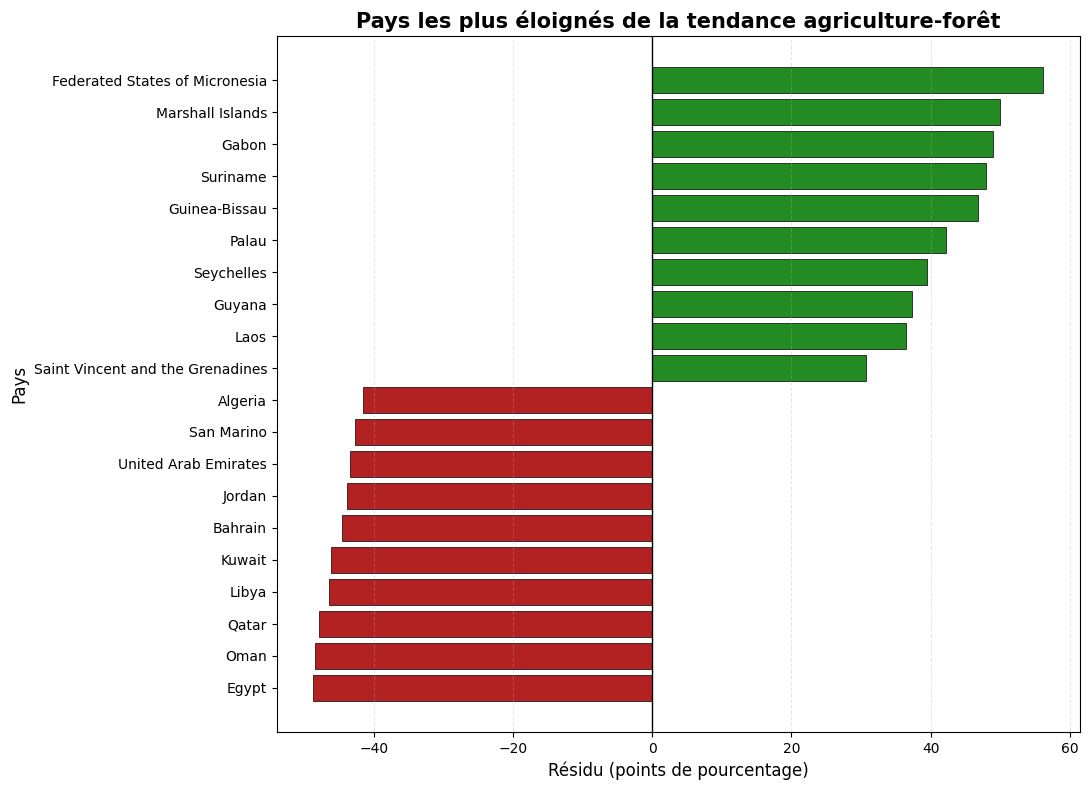

In [1590]:
# Trier les pays pour faciliter la lecture
pays_atypiques = pays_atypiques.sort_values("Residus")

# Couleur selon le signe du résidu
couleurs = [
    "forestgreen" if residu > 0 else "firebrick"
    for residu in pays_atypiques["Residus"]
]

plt.figure(figsize=(11, 8))

plt.barh(
    pays_atypiques["Country"],
    pays_atypiques["Residus"],
    color=couleurs,
    edgecolor="black",
    linewidth=0.5
)

plt.axvline(0, color="black", linewidth=1)

plt.title(
    "Pays les plus éloignés de la tendance agriculture-forêt",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Résidu (points de pourcentage)", fontsize=12)
plt.ylabel("Pays", fontsize=12)

plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

Analyse des pays les plus éloignés de la tendance agriculture-forêt

Ce graphique présente les dix pays dont la couverture forestière est la plus supérieure à la valeur prédite par notre modèle linéaire, ainsi que les dix pays dont elle est la plus inférieure.

Les barres vertes représentent les pays ayant davantage de couverture forestière que prévu, tandis que les barres rouges représentent ceux qui en ont moins.

**Pays au-dessus de la tendance :** les États fédérés de Micronésie présentent le résidu positif le plus élevé, d'environ +56 points de pourcentage. Le Gabon, le Suriname et les Îles Marshall présentent également des écarts importants. Pour ces pays, la proportion de terres agricoles ne suffit pas à expliquer leur couverture forestière élevée.

**Pays en dessous de la tendance :** l'Égypte, Oman et le Qatar présentent les résidus les plus négatifs, autour de −48 points de pourcentage. Ces pays sont situés dans des régions arides ou désertiques, ce qui suggère que le climat constitue un facteur important que notre modèle ne prend pas en compte.

**Limites de l'analyse :** les résidus mesurent uniquement l'écart à une droite ajustée sur la relation entre agriculture et forêt. Ils ne mesurent ni la qualité de la gestion forestière ni les performances environnementales d'un pays. D'autres variables, notamment le climat, la géographie et l'utilisation des sols, pourraient expliquer une partie de ces écarts.

En conclusion, cette analyse montre que la proportion de terres agricoles ne suffit pas à expliquer les différences de couverture forestière entre les pays. L'étude des pays atypiques permet ainsi d'identifier des pistes pour approfondir l'analyse environnementale.

### Répartition des pays selon leur proportion de couverture forestière

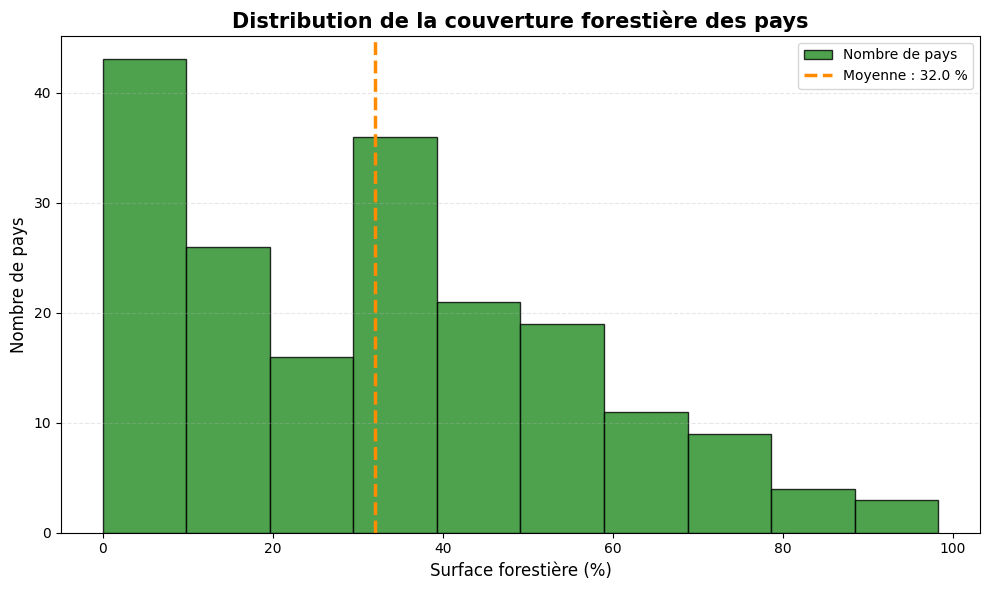

In [1591]:
donnees_foret = df["Forested Area (%)"].dropna()
moyenne_foret = donnees_foret.mean()

plt.figure(figsize=(10, 6))

# Histogramme
plt.hist(
    donnees_foret,
    bins=10,
    color="forestgreen",
    edgecolor="black",
    alpha=0.8,
    label="Nombre de pays"
)

# Ligne verticale indiquant la moyenne
plt.axvline(
    moyenne_foret,
    color="darkorange",
    linestyle="--",
    linewidth=2.5,
    label=f"Moyenne : {moyenne_foret:.1f} %"
)

# Titres et mise en forme
plt.title(
    "Distribution de la couverture forestière des pays",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Surface forestière (%)", fontsize=12)
plt.ylabel("Nombre de pays", fontsize=12)

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [1592]:
mediane_foret = donnees_foret.median()

print("Moyenne :", round(moyenne_foret, 2), "%")
print("Médiane :", round(mediane_foret, 2), "%")

Moyenne : 32.02 %
Médiane : 32.0 %


Analyse de la distribution mondiale de la couverture forestière

Cet histogramme représente la répartition des pays selon la proportion de leur territoire couvert par des forêts. Les données disponibles concernent 188 pays.

La distribution présente une concentration importante de pays dans les faibles niveaux de couverture forestière, notamment entre 0 et 10 %. Un autre groupe important apparaît entre 30 et 40 %. Le nombre de pays diminue globalement lorsque la couverture forestière dépasse 50 %, et les valeurs supérieures à 80 % restent rares.

La couverture forestière moyenne est de **32,02 %**, tandis que la médiane est de **32,00 %**. Ces deux indicateurs sont presque identiques, ce qui montre qu'ils situent le centre de la distribution à des niveaux très proches.

**Limites de l'analyse :** l'histogramme dépend du nombre et de la largeur des classes choisies. De plus, chaque pays compte ici autant qu'un autre, quelle que soit sa superficie : cette distribution ne représente donc pas la proportion de l'ensemble des terres mondiales couvertes par les forêts.

En conclusion, la couverture forestière varie fortement d'un pays à l'autre. La moyenne et la médiane se situent autour de 32 %, mais cette valeur centrale ne suffit pas à décrire toute la diversité des situations nationales.

# Carte du monde

In [1593]:
import plotly.express as px

In [1594]:
carte_foret = df.dropna(
    subset=["Country", "Forested Area (%)"]
)

fig = px.choropleth(
    carte_foret,
    locations="Country",
    locationmode="country names",
    color="Forested Area (%)",
    color_continuous_scale="Greens",
    range_color=(0, 100),
    hover_name="Country",
    hover_data={
        "Forested Area (%)": ":.1f"
    },
    title="Couverture forestière mondiale par pays"
)

fig.update_layout(
    title={
        "text": "Couverture forestière mondiale par pays (%)",
        "x": 0.5,
        "xanchor": "center",
        "font": {"size": 22}
    },
    width=1200,
    height=700,
    margin={"l": 20, "r": 80, "t": 80, "b": 20},
    geo={
        "projection_type": "natural earth",
        "showframe": False,
        "showcoastlines": True,
        "landcolor": "lightgray"
    },
    coloraxis_colorbar={
        "title": "Surface forestière (%)",
        "thickness": 18,
        "len": 0.75
    }
)

fig.show()

In [1595]:
print("Nombre de pays dans le DataFrame :", df["Country"].nunique())
print("Pays avec une couverture forestière renseignée :",
      df.dropna(subset=["Forested Area (%)"])["Country"].nunique())

Nombre de pays dans le DataFrame : 188
Pays avec une couverture forestière renseignée : 188


Analyse cartographique de la couverture forestière mondiale

Cette carte représente la proportion de la surface de chaque pays couverte par des forêts. Un dégradé de verts permet de visualiser les différences entre pays : plus le vert est foncé, plus la proportion de couverture forestière est élevée. Les valeurs peuvent être consultées en survolant les pays.

**Principales observations :**

- **Amérique du Sud :** plusieurs pays présentent une couverture forestière importante, notamment dans le bassin amazonien.
- **Afrique centrale :** le bassin du Congo se distingue également par des couvertures forestières élevées dans plusieurs pays.
- **Régions boréales :** le Canada et la Russie possèdent de vastes espaces forestiers, même si la proportion de territoire couvert varie selon les pays.
- **Régions arides :** plusieurs pays d'Afrique du Nord et du Moyen-Orient présentent une faible couverture forestière, ce qui est notamment lié aux conditions climatiques.

**Limites de l'analyse :** la carte représente des pourcentages nationaux et non les superficies forestières absolues. Un petit pays très forestier peut donc apparaître plus foncé qu'un grand pays possédant une surface forestière totale beaucoup plus importante. Les territoires gris peuvent correspondre à des données absentes ou à des territoires non représentés par le jeu de données.

**Conclusion :** cette visualisation met en évidence les fortes disparités géographiques de la couverture forestière. Elle complète les analyses statistiques précédentes en permettant de replacer les résultats dans leur contexte géographique et d'identifier les grandes régions forestières du monde.